1. Load 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prices = pd.read_csv(
    Path.cwd().parent / "data" / "processed" / "clean_prices.csv",
    index_col=0,
    parse_dates=True
).sort_index()

prices = prices[["KO", "PEP"]].dropna()
prices = prices[~prices.index.duplicated(keep="first")]

print(prices.head())
print(prices.index.min(), "to", prices.index.max())
print("Observations:", len(prices))

                   KO        PEP
Date                            
2018-01-02  34.816475  89.690910
2018-01-03  34.740017  89.455414
2018-01-04  35.229328  89.896042
2018-01-05  35.221661  90.154335
2018-01-08  35.168156  89.637733
2018-01-02 00:00:00 to 2026-10-06 00:00:00
Observations: 2202


2. Analysis

Define the walk forward function

In [2]:
def run_walk_forward(
    prices,
    train_years=4,
    test_years=1,
    window=60,
    entry_z=2.0,
    exit_z=0.5
):
    prices = prices[["KO", "PEP"]].dropna().copy()
    prices = prices.sort_index()

    log_prices = np.log(prices)
    all_returns = prices.pct_change()

    first_test = (
        prices.index.min()
        + pd.DateOffset(years=train_years)
    ).normalize()

    final_date = prices.index.max()

    results = []
    all_test_returns = []

    test_start = first_test

    while test_start <= final_date:

        test_end = test_start + pd.DateOffset(years=test_years)

        train = log_prices.loc[
            (log_prices.index >= test_start - pd.DateOffset(
                years=train_years
            ))
            & (log_prices.index < test_start)
        ]

        test = prices.loc[
            (prices.index >= test_start)
            & (prices.index < test_end)
        ]

        if len(train) < window or len(test) == 0:
            test_start = test_end
            continue

        # Estimate log(KO) = intercept + beta * log(PEP)
        x = train["PEP"].to_numpy()
        y = train["KO"].to_numpy()

        beta, intercept = np.polyfit(x, y, 1)

        # Use the training beta throughout this fold.
        history = log_prices.loc[
            (log_prices.index >= train.index.min())
            & (log_prices.index < test_end)
        ]

        spread = (
            history["KO"]
            - intercept
            - beta * history["PEP"]
        )

        rolling_mean = spread.rolling(window).mean()
        rolling_std = spread.rolling(window).std()

        zscore = (spread - rolling_mean) / rolling_std

        test_z = zscore.reindex(test.index)

        # Generate positions using test-period signals only.
        position = pd.Series(
            0.0, index=test.index, name="position"
        )

        current_position = 0.0

        for date, z in test_z.items():
            if pd.isna(z):
                position.loc[date] = current_position
                continue

            if current_position == 0:
                if z < -entry_z:
                    current_position = 1.0
                elif z > entry_z:
                    current_position = -1.0

            elif current_position == 1.0 and z >= -exit_z:
                current_position = 0.0

            elif current_position == -1.0 and z <= exit_z:
                current_position = 0.0

            position.loc[date] = current_position

        # Approximate spread returns, consistent with
        # a long-KO / short-beta-PEP spread.
        asset_returns = all_returns.reindex(test.index)

        spread_returns = (
            asset_returns["KO"]
            - beta * asset_returns["PEP"]
        )

        # Prior-day position prevents same-day lookahead.
        strategy_returns = (
            position.shift(1).fillna(0)
            * spread_returns
        )

        strategy_returns = strategy_returns.dropna()

        if len(strategy_returns) == 0:
            test_start = test_end
            continue

        equity = (1 + strategy_returns).cumprod()

        total_return = equity.iloc[-1] - 1

        sharpe = (
            np.sqrt(252)
            * strategy_returns.mean()
            / strategy_returns.std()
            if strategy_returns.std() > 0
            else np.nan
        )

        drawdown = equity / equity.cummax() - 1

        entries = (
            (position != 0)
            & (position.shift(1).fillna(0) == 0)
        ).sum()

        results.append({
            "test_start": strategy_returns.index.min(),
            "test_end": strategy_returns.index.max(),
            "beta": beta,
            "observations": len(strategy_returns),
            "total_return": total_return,
            "annualized_sharpe": sharpe,
            "max_drawdown": drawdown.min(),
            "trades": int(entries)
        })

        all_test_returns.append(strategy_returns)

        test_start = test_end

    if not results:
        raise ValueError(
            "No test folds generated. Check your data dates."
        )

    results_df = pd.DataFrame(results)

    combined_returns = pd.concat(all_test_returns).sort_index()

    return results_df, combined_returns

Run the analysis

In [3]:
wf_results, wf_returns = run_walk_forward(prices)

print(wf_results.to_string(index=False))

print("\nOverall walk-forward results")
print("----------------------------")
print(f"Total return: {(1 + wf_returns).prod() - 1:.2%}")
print(
    f"Annualized Sharpe: "
    f"{np.sqrt(252) * wf_returns.mean() / wf_returns.std():.2f}"
)
print(f"Best test year: {wf_results['total_return'].max():.2%}")
print(f"Worst test year: {wf_results['total_return'].min():.2%}")

test_start   test_end      beta  observations  total_return  annualized_sharpe  max_drawdown  trades
2022-01-03 2022-12-30  0.686537           251     -0.100271          -1.148054     -0.154624       3
2023-01-03 2023-12-29  0.788671           250      0.061760           1.225549     -0.023886       4
2024-01-02 2024-12-31  0.832146           252     -0.010219          -0.053980     -0.143012       5
2025-01-02 2025-12-31  0.870905           250     -0.213295          -1.481640     -0.294738       4
2026-01-02 2026-10-06 -0.561608           191      0.040760           0.403015     -0.175083       4

Overall walk-forward results
----------------------------
Total return: -22.58%
Annualized Sharpe: -0.40
Best test year: 6.18%
Worst test year: -21.33%


Visualize

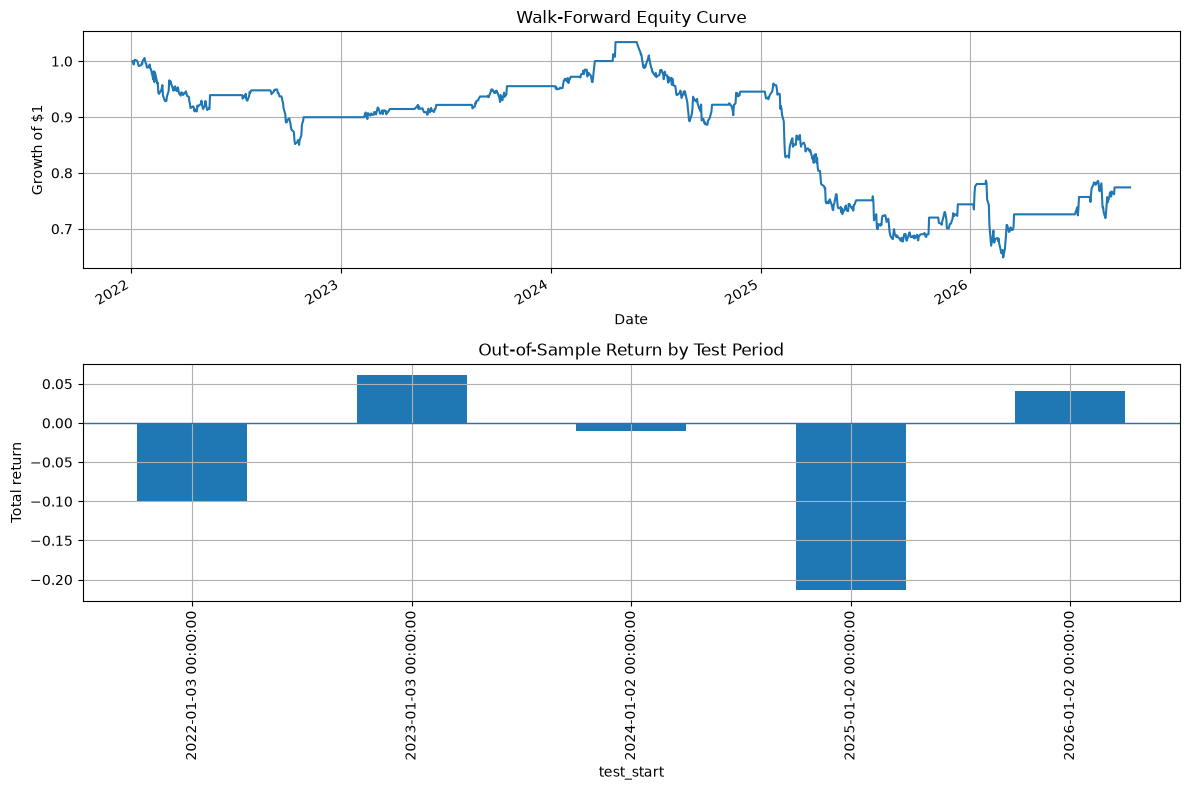

In [5]:
wf_equity = (1 + wf_returns).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

wf_equity.plot(ax=axes[0], title="Walk-Forward Equity Curve")
axes[0].set_ylabel("Growth of $1")
axes[0].grid(True)

wf_results.set_index("test_start")[
    "total_return"
].plot(
    kind="bar",
    ax=axes[1],
    title="Out-of-Sample Return by Test Period"
)

axes[1].set_ylabel("Total return")
axes[1].axhline(0, linewidth=1)
axes[1].grid(True)

plt.tight_layout()
plt.show()

3. Interpret the results: the KO/PEP pairs-trading strategy is not consistently profitable out of sample, even when the hedge ratio is periodically re-estimated.



# Trouble Shooting 
- At this point, it seems like we have to identify whether PEP and KO have consistent relationship or not.  

In [6]:
log_prices = np.log(prices[["KO", "PEP"]])

diagnostics = []

for _, row in wf_results.iterrows():
    test_start = pd.Timestamp(row["test_start"])

    train_start = test_start - pd.DateOffset(years=4)

    train = log_prices.loc[
        (log_prices.index >= train_start)
        & (log_prices.index < test_start)
    ]

    beta = np.polyfit(
        train["PEP"].to_numpy(),
        train["KO"].to_numpy(),
        1
    )[0]

    diagnostics.append({
        "test_start": test_start,
        "train_observations": len(train),
        "KO_PEP_price_corr": train["KO"].corr(train["PEP"]),
        "KO_PEP_return_corr": (
            prices.loc[train.index, "KO"].pct_change()
            .corr(
                prices.loc[train.index, "PEP"].pct_change()
            )
        ),
        "hedge_beta": beta,
    })

diagnostics_df = pd.DataFrame(diagnostics)

print(diagnostics_df.to_string(index=False))

test_start  train_observations  KO_PEP_price_corr  KO_PEP_return_corr  hedge_beta
2022-01-03                1007           0.919184            0.734207    0.686252
2023-01-03                1007           0.926080            0.753449    0.789641
2024-01-02                1006           0.937560            0.774037    0.832146
2025-01-02                1005           0.835579            0.730714    0.870905
2026-01-02                1003          -0.418896            0.691073   -0.561608


In [7]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import coint, adfuller

prices = pd.read_csv(
    Path.cwd().parent / "data" / "processed" / "clean_prices.csv",
    index_col=0,
    parse_dates=True
).sort_index()

prices = prices[["KO", "PEP"]].dropna()
log_prices = np.log(prices)

In [10]:
results = []

for _, row in wf_results.iterrows():
    test_start = pd.Timestamp(row["test_start"])
    train_start = test_start - pd.DateOffset(years=4)

    train = log_prices.loc[
        (log_prices.index >= train_start)
        & (log_prices.index < test_start)
    ]

    if len(train) < 100:
        continue

    statistic, pvalue, critical_values = coint(
        train["KO"],
        train["PEP"],
        trend="c",
        autolag="aic"
    )

    beta = np.polyfit(
        train["PEP"].to_numpy(),
        train["KO"].to_numpy(),
        1
    )[0]

    results.append({
        "test_start": test_start.date(),
        "observations": len(train),
        "beta": beta,
        "coint_t_stat": statistic,
        "p_value": pvalue,
        "critical_1pct": critical_values[0],
        "critical_5pct": critical_values[1],
        "critical_10pct": critical_values[2],
        "cointegrated_5pct": pvalue < 0.05
    })

coint_results = pd.DataFrame(results)

print(coint_results.to_string(index=False))

test_start  observations      beta  coint_t_stat  p_value  critical_1pct  critical_5pct  critical_10pct  cointegrated_5pct
2022-01-03          1007  0.686252     -3.056417 0.097396      -3.907360      -3.342210       -3.048669              False
2023-01-03          1007  0.789641     -3.287674 0.056448      -3.907360      -3.342210       -3.048669              False
2024-01-02          1006  0.832146     -3.401414 0.042194      -3.907371      -3.342216       -3.048673               True
2025-01-02          1005  0.870905     -1.325451 0.821924      -3.907382      -3.342223       -3.048677              False
2026-01-02          1003 -0.561608     -2.799276 0.165915      -3.907403      -3.342235       -3.048685              False


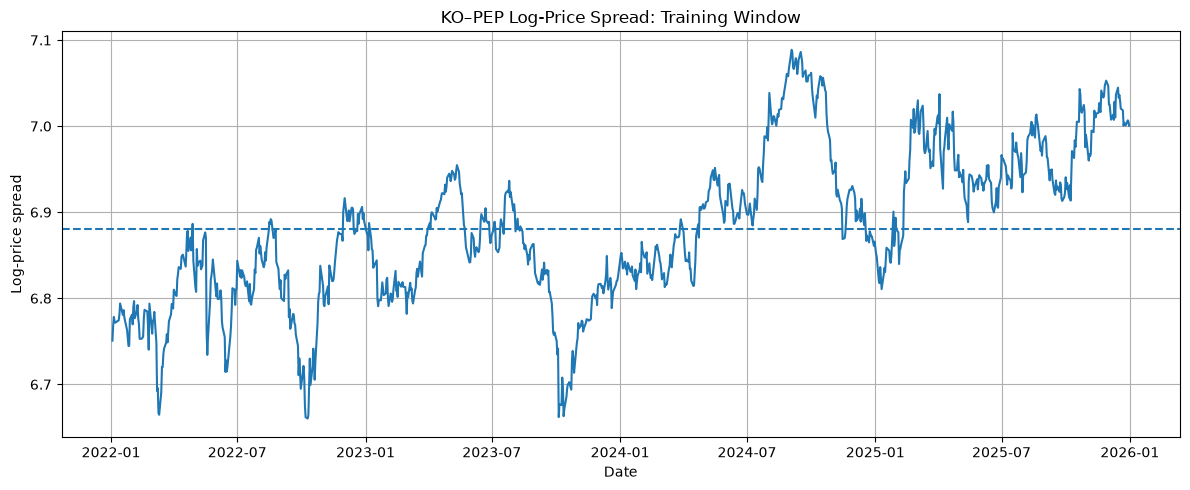

In [11]:
latest = coint_results.iloc[-1]
test_start = pd.Timestamp(latest["test_start"])

train_start = test_start - pd.DateOffset(years=4)

train = log_prices.loc[
    (log_prices.index >= train_start)
    & (log_prices.index < test_start)
]

beta = latest["beta"]

spread = train["KO"] - beta * train["PEP"]

plt.figure(figsize=(12, 5))
plt.plot(spread.index, spread)
plt.axhline(spread.mean(), linestyle="--")
plt.title("KO–PEP Log-Price Spread: Training Window")
plt.xlabel("Date")
plt.ylabel("Log-price spread")
plt.grid(True)
plt.tight_layout()
plt.show()

This indicates weak relationship... Let's find another pair that fits each other better.